In [1]:
import pandas as pd
df = pd.read_csv("DataCoSupplyChainDataset.csv", encoding="latin-1")
print(df.shape)

(180519, 53)


In [2]:
df.isna().sum().sort_values(ascending=False).head(5)

Product Description              180519
Order Zipcode                    155679
Customer Lname                        8
Customer Zipcode                      3
Days for shipment (scheduled)         0
dtype: int64

In [3]:
df["Delivery Status"].value_counts()

Delivery Status
Late delivery        98977
Advance shipping     41592
Shipping on time     32196
Shipping canceled     7754
Name: count, dtype: int64

In [4]:
df.columns = (df.columns.str.strip().str.lower().str.replace(r"[^a-z0-9]+", "_", regex=True).str.strip("_"))

In [5]:
df = df.drop(columns=["product_description", "order_zipcode"])

In [6]:
df["days_late"] = df["days_for_shipping_real"] - df["days_for_shipment_scheduled"]
df["is_late"] = (df["days_late"] > 0).astype(int)

In [7]:
df.groupby("shipping_mode")["is_late"].mean().sort_values(ascending=False)

shipping_mode
First Class       1.000000
Second Class      0.797308
Same Day          0.478279
Standard Class    0.397682
Name: is_late, dtype: float64

In [8]:
print(1 - df["is_late"].mean())

0.42720710839302234


In [9]:
df.groupby("shipping_mode")[["days_for_shipment_scheduled", "days_for_shipping_real"]].mean()

,days_for_shipment_scheduled,days_for_shipping_real
shipping_mode,,
First Class,1.0,2.000000
Same Day,0.0,0.478279
Second Class,2.0,3.990828
Standard Class,4.0,3.995907


In [10]:
valid = df[df["delivery_status"] != "Shipping canceled"]
print(1 - valid["is_late"].mean())

0.4271003964923451


In [11]:
df.to_csv("orders_clean.csv", index=False)

In [12]:
valid.groupby("order_region")["is_late"].agg(["mean", "count"]).sort_values("mean", ascending=False)

,mean,count
order_region,,
Central Africa,0.601485,1616
Western Europe,0.585302,25867
South of USA,0.585214,3855
South Asia,0.583501,7455
East Africa,0.581696,1781
East of USA,0.581684,6617
Southeast Asia,0.579794,9136
West Asia,0.578141,5746
Eastern Europe,0.576486,3785


In [13]:
valid.groupby("category_name")["is_late"].agg(["mean", "count"]).sort_values("mean", ascending=False).head(10)

,mean,count
category_name,,
Golf Bags & Carts,0.688525,61
Lacrosse,0.626140,329
Pet Supplies,0.614407,472
Cameras,0.612100,562
Accessories,0.597525,1697
Music,0.594724,417
Fitness Accessories,0.594595,296
Boxing & MMA,0.592040,402
Crafts,0.591703,458


In [14]:
valid["order_date"] = pd.to_datetime(valid["order_date_dateorders"])
valid. groupby(valid["order_date"].dt.to_period("M"))["is_late"].mean()

C:\Users\PC\AppData\Local\Temp\ipykernel_8404\2821975794.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  valid["order_date"] = pd.to_datetime(valid["order_date_dateorders"])


order_date
2015-01    0.563160
2015-02    0.578115
2015-03    0.572655
2015-04    0.561546
2015-05    0.580106
2015-06    0.566015
2015-07    0.573575
2015-08    0.584279
2015-09    0.591555
2015-10    0.572837
2015-11    0.566049
2015-12    0.570402
2016-01    0.578844
2016-02    0.565877
2016-03    0.578570
2016-04    0.576844
2016-05    0.585052
2016-06    0.593105
2016-07    0.551662
2016-08    0.570323
2016-09    0.570710
2016-10    0.567998
2016-11    0.574138
2016-12    0.584719
2017-01    0.555732
2017-02    0.573690
2017-03    0.574344
2017-04    0.562851
2017-05    0.564647
2017-06    0.560042
2017-07    0.576603
2017-08    0.585795
2017-09    0.570675
2017-10    0.557861
2017-11    0.578732
2017-12    0.577056
2018-01    0.586647
Freq: M, Name: is_late, dtype: float64

In [15]:
valid.groupby("shipping_mode")["days_late"].mean()

shipping_mode
First Class       1.000000
Same Day          0.479285
Second Class      1.993167
Standard Class   -0.006301
Name: days_late, dtype: float64

In [16]:
m = valid.groupby(valid["order_date"].dt.to_period("M"))["is_late"].mean()
print("highest:", m.idxmax(), round(m.max(), 3))
print("lowest:", m.idxmin(), round(m.min(), 3))
print(valid.groupby("shipping_mode")["days_late"].mean().round(2))


highest: 2016-06 0.593
lowest: 2016-07 0.552
shipping_mode
First Class       1.00
Same Day          0.48
Second Class      1.99
Standard Class   -0.01
Name: days_late, dtype: float64


In [17]:
f = valid[valid["shipping_mode"].isin(["First Class", "Second Class"])]
print(len(f), len(valid), round(len(f) / len(valid),3))

60319 172765 0.349


In [18]:
f = valid[valid["shipping_mode"].isin(["First Class","Second Class"])]
print("First and Second Class orders:", len(f), "of", len(valid), "=", round(100 * len(f) / len(valid), 1), "%")

First and Second Class orders: 60319 of 172765 = 34.9 %


In [19]:
late_total = valid["is_late"].sum()
late_fs = f["is_late"].sum()
print(late_total, late_fs, round(100 * late_fs / late_total, 1))
print("new late rate:", round((late_total - late_fs) / len(valid), 3))

98977 53500 54.1
new late rate: 0.263


<Axes: title={'center': 'Late rate by shipping mode'}, ylabel='shipping_mode'>

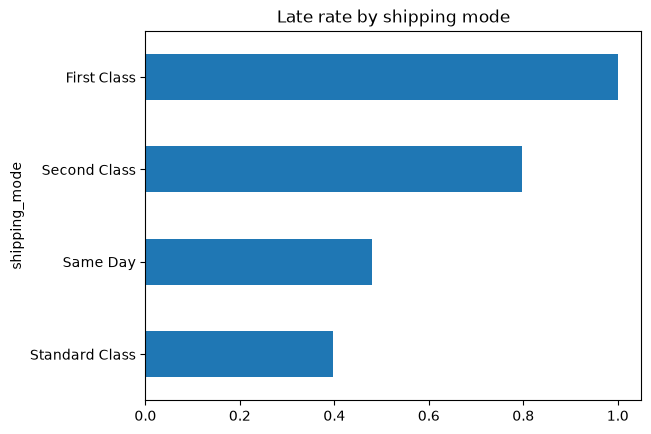

In [20]:
import matplotlib.pyplot as plt
valid.groupby("shipping_mode")["is_late"].mean().sort_values().plot(kind="barh", title="Late rate by shipping mode")

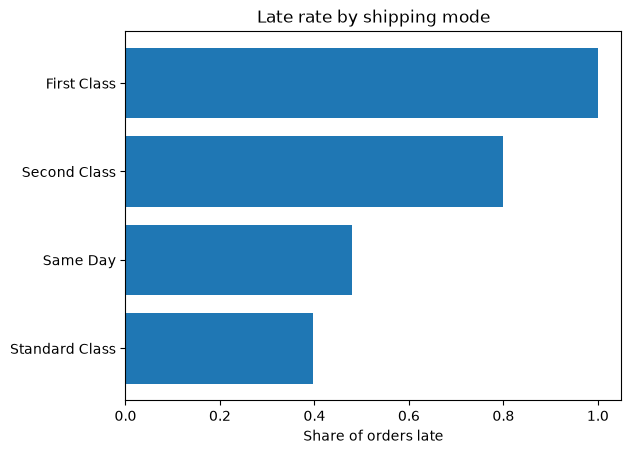

In [21]:
import matplotlib.pyplot as plt
rates = valid.groupby("shipping_mode")["is_late"].mean().sort_values()
plt.barh(rates.index, rates.values)
plt.title("Late rate by shipping mode")
plt.xlabel("Share of orders late")
plt.savefig("late_by_mode.png", bbox_inches="tight")
plt.show()

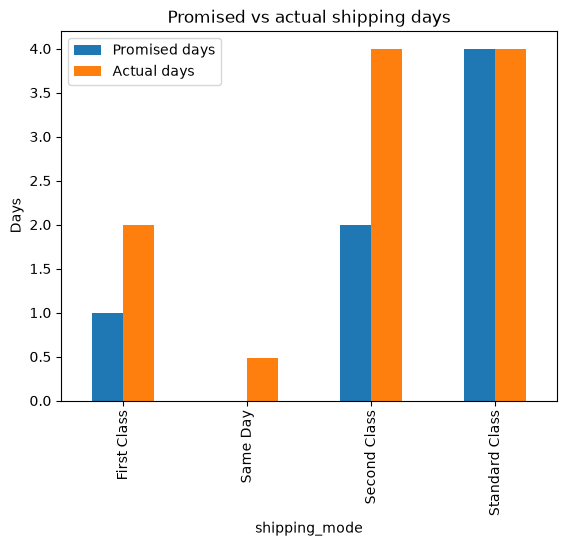

In [22]:
d = valid.groupby("shipping_mode")[["days_for_shipment_scheduled", "days_for_shipping_real"]].mean()
d.columns = ["Promised days", "Actual days"]
d.plot(kind="bar", title="Promised vs actual shipping days")
plt.ylabel("Days")
plt.savefig("promised_vs_actual.png", bbox_inches="tight")
plt.show()